# Questions & Solutions

## Can I use a geotif to derive classes & maps?

In [1]:
import pandas as pd
import geopandas as gpd
import shapely as sh
import rasterio
from rasterio.plot import show

In [2]:
dataset = rasterio.open(r'C:/Users/HP/DataScience/06_capstone/resources/36M_20250101-20251231.tif')
dataset.count   #how many bands

1

In [3]:
print(f'width:{dataset.width}, height:{dataset.height}')

width:66794, height:88550


In [4]:
dataset.bounds

BoundingBox(left=166030.0, bottom=9114500.0, right=833970.0, top=10000000.0)

In [5]:
dataset.transform

Affine(10.0, 0.0, 166030.0,
       0.0, -10.0, 10000000.0)

In [6]:
dataset.crs

CRS.from_wkt('PROJCS["WGS 84 / UTM zone 36S",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",33],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32736"]]')

(2000, 2000) uint8 1 11


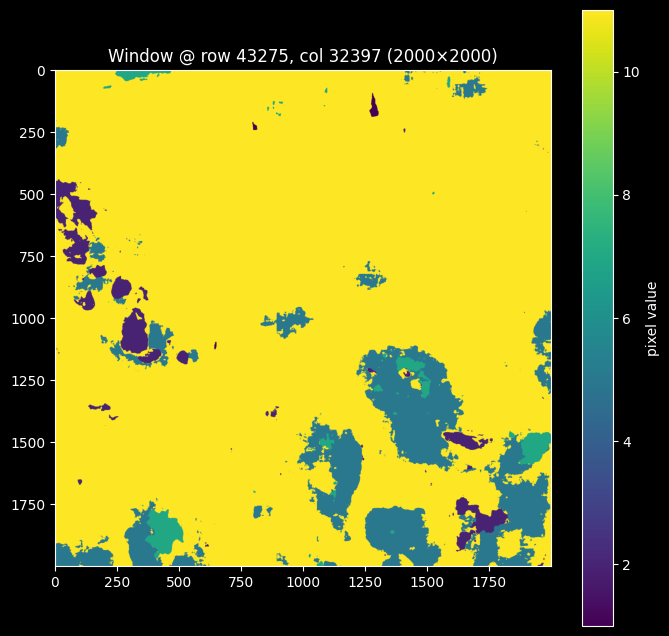

In [7]:
import rasterio
from rasterio.windows import Window
import matplotlib.pyplot as plt

fp = r'C:/Users/HP/DataScience/06_capstone/resources/36M_20250101-20251231.tif'

with rasterio.open(fp) as dataset:
    # Take a 2000 x 2000 pixel chunk from the centre of the image
    win_size = 2000
    col_off = dataset.width  // 2 - win_size // 2
    row_off = dataset.height // 2 - win_size // 2
    window = Window(col_off, row_off, win_size, win_size)

    sample = dataset.read(1, window=window)   # band 1 only, just this window
    print(sample.shape, sample.dtype, sample.min(), sample.max())

plt.figure(figsize=(8, 8))
plt.imshow(sample, cmap='viridis')
plt.colorbar(label='pixel value')
plt.title(f'Window @ row {row_off}, col {col_off} ({win_size}×{win_size})')
plt.show()

(885, 667)


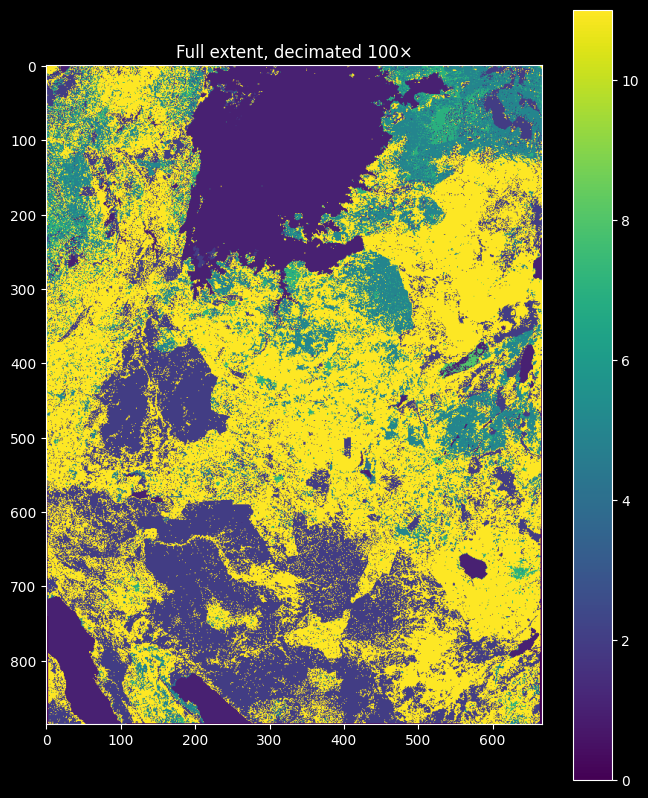

In [8]:
import rasterio
import matplotlib.pyplot as plt

with rasterio.open(fp) as dataset:
    scale = 100  # 1 output pixel per 100 source pixels
    thumb = dataset.read(1,
                         out_shape=(dataset.height // scale, dataset.width // scale)
    )
    print(thumb.shape)   # ~ (885, 667)

plt.figure(figsize=(8, 10))
plt.imshow(thumb, cmap='viridis')
plt.colorbar()
plt.title('Full extent, decimated 100×')
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_22556\657741779.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


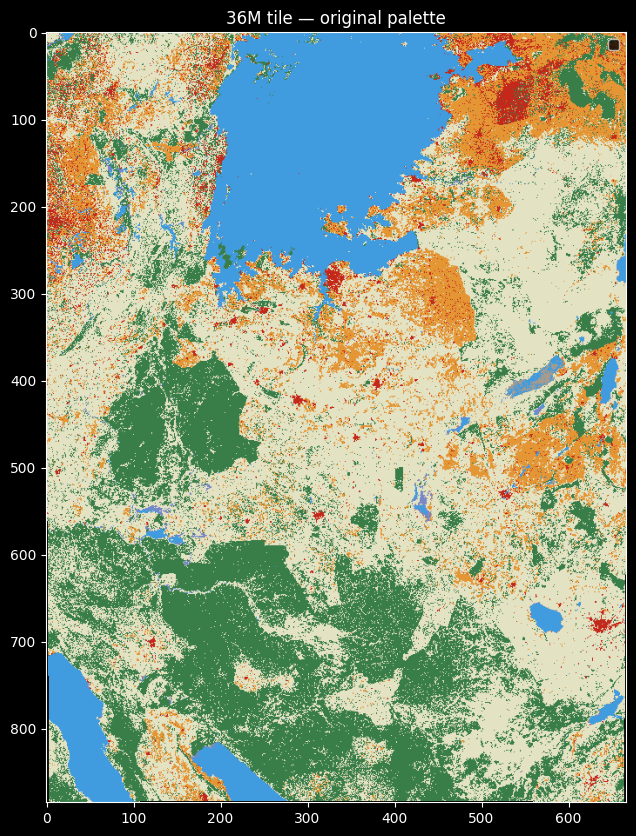

In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

fp = r'C:/Users/HP/DataScience/06_capstone/resources/36M_20250101-20251231.tif'

with rasterio.open(fp) as ds:
    scale = 100
    thumb = ds.read(1, out_shape=(ds.height // scale, ds.width // scale))
    cmap = ds.colormap(1)                       # {value: (r,g,b,a)}

# build a lookup table and map class values -> RGB
lut = np.zeros((256, 4), dtype=np.uint8)
for val, rgba in cmap.items():
    lut[val] = rgba
rgb = lut[thumb]                                # (H, W, 4) RGBA image

plt.figure(figsize=(8, 10))
plt.imshow(rgb)
plt.title('36M tile — original palette')
plt.show()


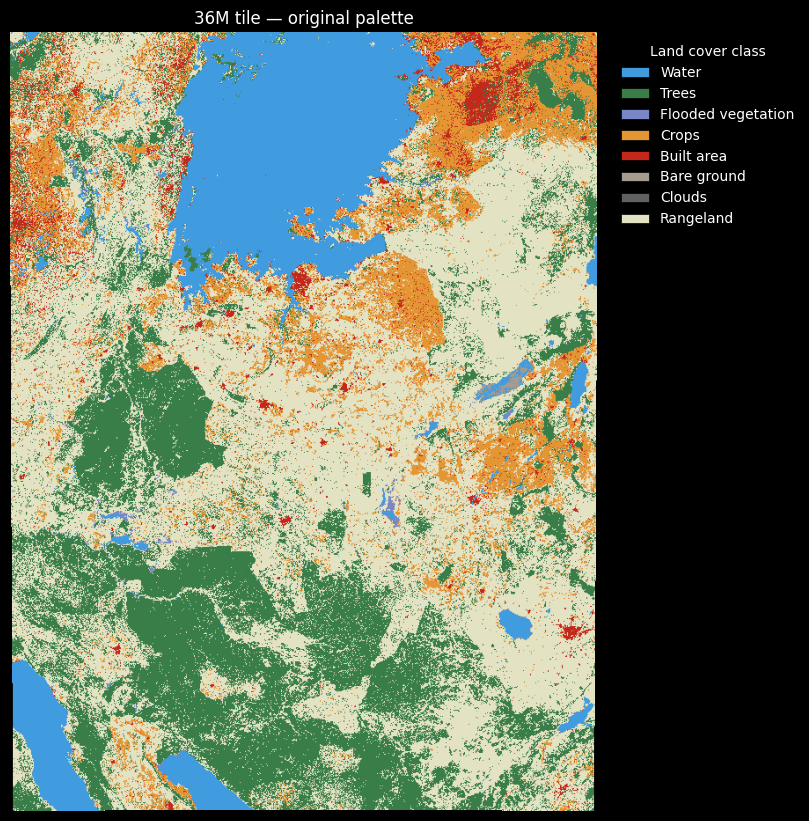

In [10]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

fp = r'C:/Users/HP/DataScience/06_capstone/resources/36M_20250101-20251231.tif'

with rasterio.open(fp) as ds:
    scale = 100
    thumb = ds.read(1, out_shape=(ds.height // scale, ds.width // scale))
    cmap = ds.colormap(1)                       # {value: (r,g,b,a)}

# build a lookup table and map class values -> RGB
lut = np.zeros((256, 4), dtype=np.uint8)
for val, rgba in cmap.items():
    lut[val] = rgba
rgb = lut[thumb]                                # (H, W, 4) RGBA image

# Esri / Impact Observatory 10 m annual land-cover class names
CLASS_NAMES = {
    1:  'Water',
    2:  'Trees',
    4:  'Flooded vegetation',
    5:  'Crops',
    7:  'Built area',
    8:  'Bare ground',
    9:  'Snow/ice',
    10: 'Clouds',
    11: 'Rangeland',
}

# one legend entry per class actually present (skip nodata = 0)
present = [v for v in np.unique(thumb) if v != 0]
handles = [
    Patch(facecolor=np.array(cmap[v]) / 255,
          edgecolor='black', linewidth=0.5,
          label=CLASS_NAMES.get(v, f'class {v}'))
    for v in present
]

plt.figure(figsize=(8, 10))
plt.imshow(rgb)
plt.title('36M tile — original palette')
plt.axis('off')
plt.legend(handles=handles, title='Land cover class',
           loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
plt.tight_layout()
plt.show()

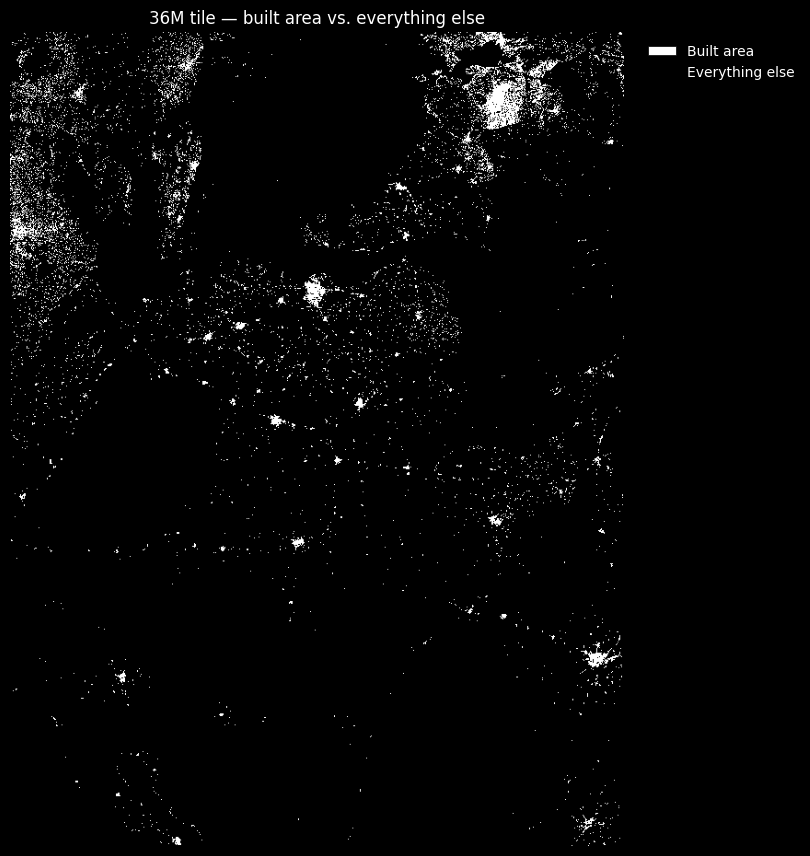

In [11]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

fp = r'C:/Users/HP/DataScience/06_capstone/resources/36M_20250101-20251231.tif'

BUILT = 7   # Esri / Impact Observatory "Built area" class value

with rasterio.open(fp) as ds:
    scale = 100
    thumb = ds.read(1, out_shape=(ds.height // scale, ds.width // scale))

# binary mask: 1 = built area, 0 = everything else
binary = (thumb == BUILT).astype(np.uint8)

# 0 -> black, 1 -> white
bw = ListedColormap(['black', 'white'])

plt.figure(figsize=(8, 10))
plt.imshow(binary, cmap=bw, vmin=0, vmax=1)
plt.title('36M tile — built area vs. everything else')
plt.axis('off')
plt.legend(
    handles=[
        Patch(facecolor='white', edgecolor='black', linewidth=0.5, label='Built area'),
        Patch(facecolor='black', edgecolor='black', linewidth=0.5, label='Everything else'),
    ],
    loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False,
)
plt.tight_layout()
plt.show()

In [13]:
import geopandas as gpd
import rasterio
from rasterio.mask import mask

fp = r'C:/Users/HP/DataScience/06_capstone/resources/36M_20250101-20251231.tif'

kenya = gpd.read_file('data/raw/ke_shp/ke.shp')
boundary = kenya.dissolve()                     # one national polygon

with rasterio.open(fp) as ds:
    boundary = boundary.to_crs(ds.crs)          # match raster CRS (UTM 36S)
    geoms = [boundary.geometry.iloc[0]]
    clipped, clipped_transform = mask(ds, geoms, crop=True)
    meta = ds.meta.copy()
    cmap = ds.colormap(1)

meta.update(height=clipped.shape[1], width=clipped.shape[2],
            transform=clipped_transform)

with rasterio.open('data/processed/36M_kenya_clip.tif', 'w', **meta) as dst:
    dst.write(clipped)
    dst.write_colormap(1, cmap)                 # preserve the palette


In [2]:
import os
import numpy as np
import geopandas as gpd
import rasterio
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from rasterio.merge import merge
from rasterio.windows import Window, from_bounds
from rasterio.features import geometry_mask

RES = r'C:/Users/HP/DataScience/06_capstone/resources'
OUT = 'data/processed'
os.makedirs(OUT, exist_ok=True)

# Tiles span 4 different UTM zones/hemispheres -> reproject all onto one grid.
TARGET_CRS = 'EPSG:32737'   # UTM zone 37S, metres (straddles equator, covers KE)

tiles = ['36M_20250101-20251231.tif', '36N_20250101-20251231.tif',
         '37M_20250101-20251231.tif', '37N_20250101-20251231.tif']
tile_paths = [os.path.join(RES, t) for t in tiles]

In [3]:
for p in tile_paths:
    with rasterio.open(p) as ds:
        print(os.path.basename(p), ds.crs, ds.width, 'x', ds.height)


36M_20250101-20251231.tif EPSG:32736 66794 x 88550
36N_20250101-20251231.tif EPSG:32636 66794 x 88550
37M_20250101-20251231.tif EPSG:32737 66794 x 88550
37N_20250101-20251231.tif EPSG:32637 66794 x 88550


## Combine & Clip reference maps

In [5]:
# --- Mosaic: virtual reprojection (WarpedVRT) + streamed merge to disk ---
# WarpedVRT reprojects lazily (nothing materialised in RAM); merge(dst_path=...)
# streams the stitched output straight to disk. nearest = categorical classes.
# NOTE: driver='GTiff' MUST be set explicitly — without it merge() tries to write
# through the VRT source band and raises "Writing through VRTSourcedRasterBand is
# not supported". Takes ~22 min over the four full tiles.

srcs = [rasterio.open(p) for p in tile_paths]
vrts = [WarpedVRT(s, crs=TARGET_CRS, resampling=Resampling.nearest) for s in srcs]

cmap = srcs[0].colormap(1)   # palette to carry through to outputs

mosaic_path = os.path.join(OUT, 'kenya_landcover_mosaic.tif')

merge(
    vrts,
    dst_path=mosaic_path,
    dst_kwds={
        'driver': 'GTiff',      # REQUIRED with VRT sources (see note above)
        'compress': 'LZW',      # class rasters compress enormously
        'tiled': True,
        'blockxsize': 512,
        'blockysize': 512,
        'BIGTIFF': 'YES',       # mosaic exceeds the 4 GB TIFF limit
    },
    nodata=0,
    resampling=Resampling.nearest,
)

for v in vrts:
    v.close()
for s in srcs:
    s.close()

# merge() does not copy the palette — reattach it
with rasterio.open(mosaic_path, 'r+') as ds:
    ds.write_colormap(1, cmap)

print('mosaic written:', mosaic_path)

KeyboardInterrupt: 

In [ ]:
# --- Clip mosaic to Kenya, processed in row-blocks (low memory) ---
# Uses the complete boundary at data/raw/ke_shp/ke.shp (47 counties -> dissolve).
kenya = gpd.read_file('data/raw/ke_shp/ke.shp').dissolve().to_crs(TARGET_CRS)
kenya_geom = [kenya.geometry.iloc[0]]

clip_path = os.path.join(OUT, 'kenya_landcover_clipped.tif')

with rasterio.open(mosaic_path) as src:
    # window covering only Kenya's bounding box
    minx, miny, maxx, maxy = kenya.total_bounds
    win = from_bounds(minx, miny, maxx, maxy,
                      src.transform).round_offsets().round_lengths()
    win_w, win_h = int(win.width), int(win.height)

    profile = src.profile.copy()
    profile.update(
        height=win_h, width=win_w,
        transform=src.window_transform(win),
        compress='LZW', tiled=True, blockxsize=512, blockysize=512,
        BIGTIFF='YES', nodata=0,
    )

    with rasterio.open(clip_path, 'w', **profile) as dst:
        dst.write_colormap(1, cmap)
        block = 2048
        for row in range(0, win_h, block):
            h = min(block, win_h - row)
            src_win = Window(win.col_off, win.row_off + row, win_w, h)
            data = src.read(1, window=src_win)
            strip_transform = src.window_transform(src_win)
            # True where OUTSIDE the polygon -> set to nodata (0)
            outside = geometry_mask(kenya_geom, out_shape=(h, win_w),
                                    transform=strip_transform, invert=False)
            data[outside] = 0
            dst.write(data, 1, window=Window(0, row, win_w, h))

print('clipped to Kenya:', clip_path)

In [ ]:
# --- Preview the clipped result with the original palette ---
with rasterio.open(clip_path) as ds:
    scale = 100
    thumb = ds.read(1, out_shape=(ds.height // scale, ds.width // scale))
    cmap = ds.colormap(1)

# class value -> RGBA lookup table
lut = np.zeros((256, 4), dtype=np.uint8)
for v, rgba in cmap.items():
    lut[v] = rgba

# per-class pixel counts (excluding nodata=0) for the degradation analysis
vals, counts = np.unique(thumb, return_counts=True)
for v, c in zip(vals, counts):
    if v != 0:
        print(f'class {v:>3}: {c:>10,} px')

plt.figure(figsize=(10, 10))
plt.imshow(lut[thumb])
plt.title('Kenya land cover — mosaicked (UTM 37S), clipped')
plt.axis('off')
plt.show()